In [107]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [11]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [63]:
categorical = df.select_dtypes(include=["object", "string"]).columns.tolist()
numerical = df.select_dtypes(include=np.number).columns.drop("converted").tolist()

In [64]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [65]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [66]:
df_full_train.shape

(4000, 9)

In [67]:
df_test.shape

(1000, 9)

In [68]:
df_val.shape

(1000, 9)

In [69]:
df_train.shape

(3000, 9)

In [70]:
from sklearn.metrics import roc_auc_score

In [71]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [72]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [73]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [74]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [75]:
from sklearn.feature_extraction import DictVectorizer

# Question 1

In [76]:
for c in numerical:
    print(c, roc_auc_score(y_train, df_train[c].values))

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


# Question 2

In [77]:
from sklearn.linear_model import LogisticRegression

In [134]:
def train(df_train, y_train, C=1):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [79]:
dv, model = train(df_train, y_train)

In [91]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [93]:
y_pred = predict(df_val, dv, model)

In [95]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

# Question 3

In [104]:
scores = []
thresholds = np.linspace(0.0, 1.0, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_positive & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    scores.append((t, tp, fp, fn, tn, precision, recall))


/tmp/ipykernel_151698/1229731091.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


In [111]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,threshold,tp,fp,fn,tn,precision,recall
0,0.00,586,414,0,414,0.586,1.000000
1,0.01,586,414,0,414,0.586,1.000000
2,0.02,586,414,0,414,0.586,1.000000
3,0.03,586,414,0,414,0.586,1.000000
4,0.04,586,414,0,414,0.586,1.000000
...,...,...,...,...,...,...,...
96,0.96,1,0,585,0,1.000,0.001706
97,0.97,0,0,586,0,NaN,0.000000
98,0.98,0,0,586,0,NaN,0.000000
99,0.99,0,0,586,0,NaN,0.000000


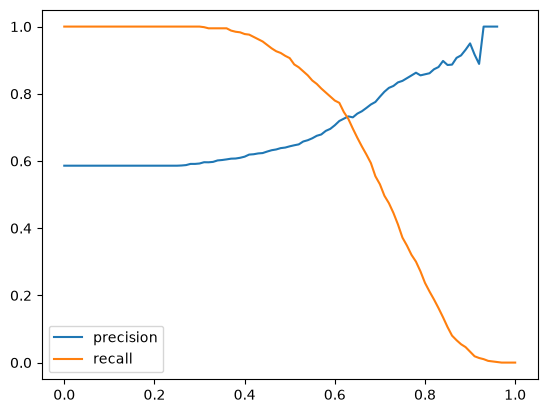

In [112]:
plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.legend()

In [120]:
thresholds[np.abs(df_scores['precision'] - df_scores['recall']).argmin()]

np.float64(0.63)

# Question 4

In [121]:
scores = []
thresholds = np.linspace(0.0, 1.0, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_positive & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    f1 = 2 * (precision * recall) / (precision + recall)

    scores.append((t, tp, fp, fn, tn, precision, recall, f1))

/tmp/ipykernel_151698/128916275.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


In [123]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'f1']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,threshold,tp,fp,fn,tn,precision,recall,f1
0,0.00,586,414,0,414,0.586,1.000000,0.738966
1,0.01,586,414,0,414,0.586,1.000000,0.738966
2,0.02,586,414,0,414,0.586,1.000000,0.738966
3,0.03,586,414,0,414,0.586,1.000000,0.738966
4,0.04,586,414,0,414,0.586,1.000000,0.738966
...,...,...,...,...,...,...,...,...
96,0.96,1,0,585,0,1.000,0.001706,0.003407
97,0.97,0,0,586,0,NaN,0.000000,NaN
98,0.98,0,0,586,0,NaN,0.000000,NaN
99,0.99,0,0,586,0,NaN,0.000000,NaN


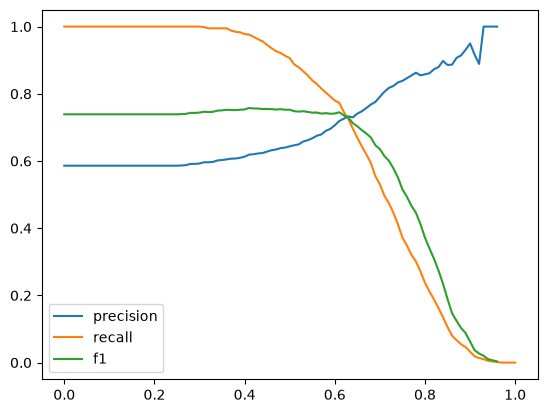

In [124]:
plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.plot(df_scores.threshold, df_scores['f1'], label='f1')

plt.legend()

In [127]:
thresholds[df_scores['f1'].argmax()]

np.float64(0.41000000000000003)

# Question 5

In [128]:
from sklearn.model_selection import KFold

In [129]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [131]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [132]:
scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [133]:
np.std(scores)

np.float64(0.006853233151022138)

# Question 6

In [137]:
results = []

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    results.append([C, np.mean(scores), np.std(scores)])

In [138]:
results

[[1e-06, np.float64(0.6167342250714795), np.float64(0.018669799234831475)],
 [0.001, np.float64(0.7491721776030379), np.float64(0.009996375455700753)],
 [1, np.float64(0.7317269710972524), np.float64(0.006853233151022138)]]